Now that the 3x3x3 space time grid around an observational point has been extracted and analyzed for summary statistics, the statistics of each year, season, and region will be analyzed to determine where the model is strongest and where it is weakest. 

In [22]:
#Very first step is to import these modules and libraries into the satprocessing kernel
import numpy as np
import dask as ds
import earthaccess as ea
import xarray as xr
import sys
import matplotlib.pyplot as plt
import requests
import pandas as pd
import PyCO2SYS as pyco2
import cartopy
from shapely.ops import unary_union
import cartopy.feature as cfeature
from datetime import date
from scipy.spatial import KDTree
from datasets import Dataset
import geopandas as gpd
import rioxarray
from shapely.geometry import mapping
print("module import success")

import sys
sys.path.append(r'C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\RESOURCES\\python\\utilities\\bootstrap\\')
print("path import success")

import pprint
from environment import bootstrap_environment  
pprint.pprint(bootstrap_environment(preferred="edmund_gable"))
print("success")

from utilities.bootstrap.environment import bootstrap_environment
env = bootstrap_environment(preferred="edmund.gable")
env
print("utilities import success")

#Before this next step, install the library 'resource': conda install -c conda-forge resource
from utilities import get_dates, get_source_file_dates, find_text
find_text("stats")

from utilities import get_prod_files 
get_prod_files("DO", period="DOY")
#"DOY" is climatological 'day of year
#'W' is climatological weekly files

from pathlib import Path

root = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026")
raw_data = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data")
model_data = Path(r"Z:\\MOM6\Hindcasts\\BTM-O2-REGRID")
processed_data=Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison")




module import success
path import success
⚠ Unrecognized preferred label 'edmund_gable'. Valid options: ['NECMAC04363461.local', 'nefscsatdata', 'guihyde', 'Mac.localdomain', 'gdavis', 'egable']
{'dataset_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/DATASETS'),
 'hostname': 'NECL04363598',
 'lookuptable_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/lookuptables'),
 'metadata_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/metadata'),
 'project_root': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'python_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'satlogs_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/logs/satprocessing'),
 'timestamp': datetime.datetime(2026, 6, 22, 16, 42, 51, 627076),
 'utilities_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RE

In [6]:
def stats(df, subset):
   
    # 1. Display point-by-point delta difference
    print(f"Mean of delta difference between model 3x3x3 grid data and observational data in {subset} is: {np.nanmean(df['delta_difference_grid']):4f}")
    print(f"Mean of delta difference between model exact grid data and observational data in {subset} is: {np.nanmean(df['delta_difference_point']):4f}")
    # 2. Calculate Global Dataset RMSE
    # RMSE is the square root of the mean of squared differences between model and observations
    global_rmse_grid = np.sqrt(np.nanmean(df['delta_difference_grid'] ** 2))
    print(f"Global RMSE (3x3x3 grid vs obs) between model and observations in {subset} is: {global_rmse_grid:.4f}")
    
# Exact Match RMSE (Slices down to only where valid exact pairs exist)
    valid_exact = df.dropna(subset=['delta_difference_point'])
    global_rmse_exact = np.sqrt((valid_exact['delta_difference_point'] ** 2).mean())
    print(f"Global RMSE (Exact point vs Obs) between model and observations in {subset} is: {global_rmse_exact:.4f}")
    print(f"-> Calculated using {len(valid_exact)} valid exact points in {subset} (out of {len(df)} total pairs).")

    # 5. Calculate Global Statistics using Grand Variance formulas (assuming N=27 for each grid)
    global_mean = df['cube_mean'].mean()
    obs_mean=df['dissolved_oxygen'].mean()
    
    # Combined variance formula: mean of variances + variance of means
    mean_of_variance=(df['cube_std']**2).mean()
    variance_of_means=df['cube_mean'].var()

    global_variance = mean_of_variance + variance_of_means
    global_std = np.sqrt(global_variance)
    
    print(f"Calculated Observational Mean: {obs_mean:.4f}")
    print(f"Calculated Model Global Mean: {global_mean:.4f}")
    print(f"Calculated Global Std Dev: {global_std:.4f}")
    over_est_pct=(df['delta_difference_grid']>0).mean()*100
    under_est_pct=(df['delta_difference_grid']<0).mean()*100
    print(f"Model grid overestimates the data {over_est_pct} percent of the time")
    print(f"Model grid underestimates the data {under_est_pct} percent of the time")
    avg_overestimation = df[df['delta_difference_grid'] > 0]['delta_difference_grid'].mean()
    avg_underestimation = df[df['delta_difference_grid'] < 0]['delta_difference_grid'].mean()

    print(f"When overestimating, the average excess oxygen is: {avg_overestimation:.4f}")
    print(f"When underestimating, the average deficit oxygen is: {avg_underestimation:.4f}")

    # Calculate the standard deviation of your real-world observations
    obs_std = df['dissolved_oxygen'].std()

    print(f"Real-World Observational STD: {obs_std:.4f}")
    print(f"Model Global STD: {global_std:.4f}")

# Compare them
    std_ratio = global_std / obs_std
    print(f"Model-to-Observation Variance Ratio: {std_ratio:.2f}")
    
    # 6. Calculate Global Z-score for each observational point
    df['global_z_score'] = (df['dissolved_oxygen'] - global_mean) / global_std
    
    
    stressed_obs = df[df['DO_status'] != 'Oxygenated']
    stressed_mod=df[df['model_DO_status'] != 'Oxygenated']
    
    if len(stressed_obs) > 0:
        # 2. Calculate how often the model status matches the observation status exactly
        status_matches = (stressed_obs['DO_status'] == stressed_obs['model_DO_status']).sum()
        match_rate = (status_matches / len(stressed_mod)) * 100
        false_positive = ((df['model_DO_status'] != 'Oxygenated') & (df['model_DO_status'] != df['DO_status'])).sum()
        false_negative = ((df['model_DO_status'] == 'Oxygenated') & (df['model_DO_status'] != df['DO_status'])).sum()
        #mod_len = len(stressed_mod) if len(stressed_mod) > 0 else 1
        fpp=(false_positive / len(stressed_mod))*100
        fnp=(false_negative / len(stressed_obs))*100
        
        print(f"\n===========================================================")
        print(f"OXYGEN STATUS MATCH METRICS (Excluding 'oxygenated')")
        print(f"===========================================================")
        print(f"Total observations showing stressed conditions: {len(stressed_obs)}")
        print(f"Total model outputs showing stressed conditions: {len(stressed_mod)}")
        print(f'False Positives: Of the {len(stressed_mod)} times the model predicted stress, {fpp:.2f}% were false alarms')
        print(f'False Negatives: Of the {len(stressed_obs)} times the observations detected stress, {fnp:.2f}% were missed by the model')
        print(f"Overall Model Match Accuracy: {match_rate:.2f}%")
        print(f"-----------------------------------------------------------")
   
    # 1. Gather all metrics into a dictionary
    metrics={'Subset': subset,
      'Mean_Delta_Grid': np.nanmean(df['delta_difference_grid']),
      'Mean_Delta_Point': np.nanmean(df['delta_difference_point']),
      'Global_RMSE_Grid': np.sqrt(np.nanmean(df['delta_difference_grid'] ** 2)),
      'Global_RMSE_Exact': np.sqrt((df.dropna(subset=['delta_difference_point'])['delta_difference_point'] ** 2).mean()) if df['delta_difference_point'].notna().any() else np.nan,
      'Model_Global_Mean': df['cube_mean'].mean(),
      'Obs_Mean': df['dissolved_oxygen'].mean(),
      'Global_Std_Dev': np.sqrt((df['cube_std']**2).mean() + df['cube_mean'].var()),
      'Obs_Std_Dev': df['dissolved_oxygen'].std(),
      'Variance_Ratio': np.sqrt((df['cube_std']**2).mean() + df['cube_mean'].var()) / df['dissolved_oxygen'].std() if df['dissolved_oxygen'].std() != 0 else np.nan,
      'Overestimate_Pct': (df['delta_difference_grid'] > 0).mean() * 100,
      'Underestimate_Pct': (df['delta_difference_grid'] < 0).mean() * 100,
      'Avg_Overestimation': df[df['delta_difference_grid'] > 0]['delta_difference_grid'].mean(),
      'Avg_Underestimation': df[df['delta_difference_grid'] < 0]['delta_difference_grid'].mean(),
      'Total_Stressed_Obs': len(stressed_obs),
      'Total_Stressed_Mod': len(stressed_mod),
      'False_Positives_Pct': fpp if len(stressed_obs) > 0 else np.nan,
      'False_Negatives_Pct': fnp if len(stressed_obs) > 0 else np.nan,
      'Overall_Match_Accuracy': match_rate if len(stressed_obs) > 0 else np.nan
    }
    
    return metrics  # Change from returning 'df' to returning the 'metrics' dict
    

In [2]:
def plot_model_vs_obs_with_trend(df, label):
    # Drop NaNs to ensure clean plotting and calculations
    plot_df = df.dropna(subset=['dissolved_oxygen', 'closest_model_val']).copy()
    
    x_data = plot_df['dissolved_oxygen']
    y_data = plot_df['closest_model_val']
    
    plt.figure(figsize=(8, 7))
    
    # 1. Core Scatter plot
    plt.scatter(
        x_data, 
        y_data, 
        s=20, 
        color='#1f77b4', 
        alpha=0.4, 
        edgecolors='none', 
        label='Data Points'
    )
    
    # 2. Dynamic 1:1 Line of Perfect Agreement
    min_val = min(x_data.min(), y_data.min())
    max_val = max(x_data.max(), y_data.max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='1:1 Line')
    
    # 3. Calculate and Plot the ACTUAL Linear Relationship Line
    # np.polyfit calculates the slope (m) and intercept (c) for y = mx + c
    slope, intercept = np.polyfit(x_data, y_data, 1)
    x_trend = np.linspace(min_val, max_val, 100)
    y_trend = slope * x_trend + intercept
    
    plt.plot(
        x_trend, 
        y_trend, 
        color='black', 
        linestyle='-', 
        linewidth=2, 
        label=f'Actual Trend (Slope = {slope:.2f})'
    )
    
    # 4. Calculate Pearson Correlation (R)
    r_val = x_data.corr(y_data)
    
    # 5. Formatting
    plt.title(f"Bottom Ocean Dissolved Oxygen in {label}: Model vs. Observations\nR = {r_val:.2f} | Trend Slope = {slope:.2f}", fontsize=12)
    plt.xlabel("Observational Dissolved Oxygen", fontsize=11)
    plt.ylabel("Model Dissolved Oxygen (Closest Window)", fontsize=11)
    
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.legend(loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

In [3]:
def analyze_temporal_data(df, output_path):
    # Ensure there are no null dates
    valid_dates_df = df.dropna(subset=['matched_time']).copy()
    all_summary_rows=[]
    
    # Get a sorted list of unique years in the dataset
    unique_years = sorted(valid_dates_df['matched_time'].dt.year.unique())
    
    for year in unique_years:
        print(f"\n###########################################################")
        print(f"               RUNNING STATISTICS FOR YEAR: {year}        ")
        print(f"###########################################################")
        
        # Filter the dataframe for just this year
        year_df = valid_dates_df[valid_dates_df['matched_time'].dt.year == year]
        
        # Call your stats function (make sure to pass a copy so you don't trigger settings warnings)
        year_metrics=stats(year_df.copy(), subset=str(year))
        all_summary_rows.append(year_metrics)
        plot_model_vs_obs_with_trend(year_df, label = str(year))


        
    def get_season(month):
        if month in [3, 4, 5]: return 'Spring'
        elif month in [6, 7, 8]: return 'Summer'
        elif month in [9, 10, 11]: return 'Fall'
        else: return 'Winter'
       
        
    valid_dates_df['season'] = valid_dates_df['matched_time'].dt.month.map(get_season)
    seasons_order = ['Spring', 'Summer', 'Fall', 'Winter']
    
    for season in seasons_order:
        season_df = valid_dates_df[valid_dates_df['season'] == season]
        if len(season_df) == 0:
            continue
            
        print(f"\n===========================================================")
        print(f"               RUNNING STATISTICS FOR SEASON: {season}     ")
        print(f"===========================================================")
        
        # Capture the dictionary returned by stats()
        season_metrics = stats(season_df.copy(), subset=f"Season_{season}")
        all_summary_rows.append(season_metrics)
        plot_model_vs_obs_with_trend(season_df, label=season)
    # ----------------------------------
    # PART 3: EXPORT TO CSV
    # ----------------------------------
    summary_df = pd.DataFrame(all_summary_rows)
    summary_df.to_csv(output_path, index=False)
    print(f"\n[SUCCESS] All statistics successfully exported to: {output_path}")    


In [4]:
def analyze_seasons(df):
    valid_dates_df = df.dropna(subset=['matched_time']).copy()
    
    # Define a helper function to map months to seasons
    def get_season(month):
        if month in [3, 4, 5]:
            return 'Spring'
        elif month in [6, 7, 8]:
            return 'Summer'
        elif month in [9, 10, 11]:
            return 'Fall'
        else: # 12, 1, 2
            return 'Winter'
            
    # Create the season column
    valid_dates_df['season'] = valid_dates_df['matched_time'].dt.month.map(get_season)
    
    # Loop through seasons in chronological order
    seasons_order = ['Spring', 'Summer', 'Fall', 'Winter']
    for season in seasons_order:
        # Check if the season actually exists in the data subset
        season_df = valid_dates_df[valid_dates_df['season'] == season]
        if len(season_df) == 0:
            continue
            
        print(f"\n###########################################################")
        print(f"               RUNNING STATISTICS FOR SEASON: {season}     ")
        print(f"###########################################################")
        
        stats(season_df.copy(), subset=season)

In [5]:

df=pd.read_csv(processed_data / 'complete' / 'ECOMON_MOM6_3x3x3_comparison.csv') 
df['matched_time'] = pd.to_datetime(df['matched_time'], errors='coerce')
final = analyze_temporal_data(df, processed_data / 'complete' / 'ECOMON_MOM6_stats.csv')
final



###########################################################
               RUNNING STATISTICS FOR YEAR: 2009        
###########################################################


NameError: name 'stats' is not defined

In [ ]:
df=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\ECOMON_MOM6_3x3x3_comparison.csv")
print(df.columns.to_list())


['Unnamed: 0.1', 'Unnamed: 0', 'id', 'lat', 'lon', 'obs_depth', 'bottom_depth', 'dissolved_oxygen', 'DO_status', 'grid_id', 'matched_time', 'matched_lat', 'matched_lon', 'exact_model_val', 'cube_mean', 'cube_std', 'cube_min', 'cube_max', 'closest_model_val', 'closest_grid_id', 'closest_lat', 'closest_lon', 'closest_time', 'delta_difference_point', 'delta_difference_grid', 'local_z_score', 'global_z_score', 'model_DO_status']


MissingSpatialDimensionError: x dimension (matched_lon) not found.

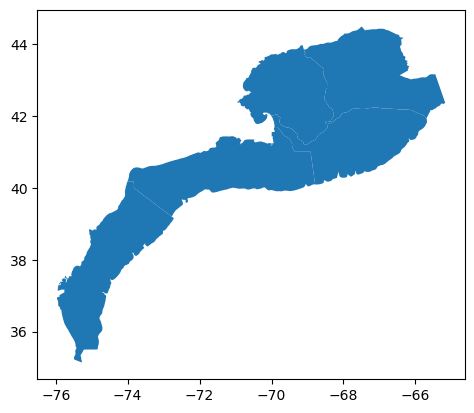

In [33]:
#url = 'https://comet.nefsc.noaa.gov/erddap/griddap/noaa_coastwatch_acspo_v2_reanalysis.nc?sea_surface_temperature%5B(2025-06-01T12:00:00Z):1:(2025-06-30T12:00:00Z)%5D%5B(34):1:(46)%5D%5B(-77):1:(-63)%5D'
#url_new = requests.get(url,verify=False).content
#ds = xr.open_dataset(url_new)
#ds=xr.open_dataset(r"Z:\MOM6\Hindcasts\BTM-O2-REGRID\2001\01\CEFI-BTM_O2-HINDCAST-20010101.nc")


gdf = gpd.read_file('https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip')
shapefile=gpd.read_file('https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip')
shapefile.plot()
# rioxarray requires spatial dimensions and CRS to be set
ds.rio.set_spatial_dims(x_dim="matched_lon", y_dim="matched_lat", inplace=True)
ds.rio.write_crs("epsg:4326", inplace=True)

# Clip the dataset
clipped_ds = ds.rio.clip(gdf.geometry.apply(mapping), gdf.crs, drop=True)
clipped_ds.dissolved_oxygen.plot()


Shapefile CRS is missing! Assigning epsg:4326...


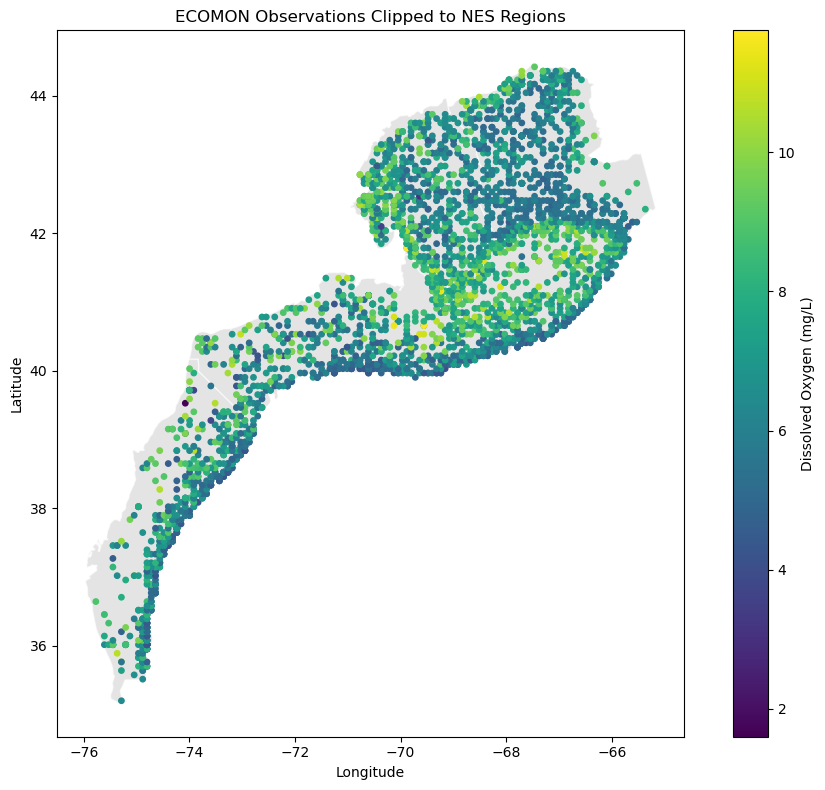

In [36]:
df = pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\ECOMON_MOM6_3x3x3_comparison.csv")

# 2. Convert DataFrame directly into a GeoDataFrame 
# (Always put Longitude/X first, then Latitude/Y)
gdf_points = gpd.GeoDataFrame(
    df, 
    geometry=gpd.points_from_xy(df['matched_lon'], df['matched_lat']),
    crs="epsg:4326"
)

# 3. Load the 5-region Northeast Shelf shapefile
shapefile_url = 'https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip'
gdf_shapes = gpd.read_file(shapefile_url)

# FIX: If the shapefile has no CRS, explicitly assign it
if gdf_shapes.crs is None:
    print("Shapefile CRS is missing! Assigning epsg:4326...")
    gdf_shapes.set_crs("epsg:4326", inplace=True)

# Now it is safe to ensure the point data and shapefile match perfectly
if gdf_shapes.crs != gdf_points.crs:
    gdf_shapes = gdf_shapes.to_crs(gdf_points.crs)

# 4. Perform the Spatial Clip (Drops all cruise points outside the shapefile boundaries)
clipped_points = gpd.clip(gdf_points, gdf_shapes)

# 5. Plot the result
fig, ax = plt.subplots(figsize=(10, 8))

# Draw the background polygon regions
gdf_shapes.plot(ax=ax, color='lightgray', edgecolor='white', alpha=0.6, label='NES Regions')

# Overlay your clipped cruise data points, color-coded by Dissolved Oxygen
clipped_points.plot(
    ax=ax, 
    column='dissolved_oxygen', 
    cmap='viridis', 
    legend=True, 
    markersize=15,
    legend_kwds={'label': "Dissolved Oxygen (mg/L)"}
)

plt.title("ECOMON Observations Clipped to NES Regions")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()